# M5 midterm results: winner LightGBM blended with zero-shot Chronos-2

This notebook reproduces the main results from the saved forecasts in `forecasts/`. No model training is needed.
Part 1 shows the saved result files. Part 2 re-scores the winner and the blend on all six windows if you have the M5 data. Part 3 shows the summary table and figures.

Rule fixed before the final window was scored: 20 percent direct zero-shot Chronos-2 B (weekday, event and SNAP covariates, mean point) at levels 1 to 9, winner alone at levels 10 to 12.
We do not claim to beat the M5 winner. Full explanation: `docs/REPORT.md`.

Set `DATA_DIR` below to the folder holding the M5 files (see `data/README.md`). Without it, only parts 1 and 3 run.

In [1]:
import os, sys, glob, shutil, argparse
import numpy as np
ROOT = os.path.abspath(".")
sys.path.insert(0, os.path.join(ROOT, "src"))
DATA_DIR = r"M5_DATA_FOLDER"   # change to your M5 folder (needs 1,969 days of sales for the final window)
os.makedirs("inputs", exist_ok=True)
for pat in ["forecasts/winner_lightgbm/winner_*.npy", "forecasts/chronos2_aggregate/agg_chronos2_B_covariates_*.npy"]:
    for f in glob.glob(pat):
        shutil.copy(f, os.path.join("inputs", os.path.basename(f)))
print("inputs ready:", len(os.listdir("inputs")), "files; M5 data found:", os.path.isdir(DATA_DIR))

inputs ready: 12 files; M5 data found: False


## 1. Saved results (no data needed)

The next two cells print the result files as produced on the lab machines: first the five-window file, then the final-window analysis.

In [2]:
print(open("results/04_six_window_blend/results_multiwindow.txt").read())

MULTI-WINDOW CHECK: winner (six-set LightGBM average) vs blend with direct Chronos-2 at levels 1 to 9
Fixed rule: share 0.20, direct Chronos-2 with covariates, mean point, levels 1 to 9 only. Reconciled = same blend, then OLS reconciliation (secondary).
WRMSSE over 12 levels, lower is better. Bootstrap per window: 2000 draws, blocks of 7 days (days only, rough guide). Days in data folder: 1941.

WINDOW cv5 (forecast d_1802..d_1829) | sales growth vs previous 28 days +8.5% | winner bias 0.925
Variant                      WRMSSE   Change    95% interval of change  P(better)
winner alone                 0.6730  +0.0000        [+0.0000, +0.0000]
blend (headline)             0.6545  -0.0185        [-0.0285, -0.0078]       1.00
blend + OLS reconciled       0.6577  -0.0153        [-0.0241, -0.0061]       1.00
blend share 0.10             0.6628  -0.0102        [-0.0153, -0.0048]       1.00
blend share 0.30             0.6483  -0.0247        [-0.0396, -0.0087]       1.00
  OLS solver relative 

In [3]:
print(open("results/06_ablation_bootstrap/results_final_analysis.txt").read())

ABLATION, UNCERTAINTY AND SECONDARY OUTCOMES FOR THE BLEND (winner + direct Chronos-2 at levels 1 to 9)
Fixed share 0.20 unless stated. WRMSSE over 12 levels, lower is better. Bootstrap: 2000 draws, circular blocks of 7 days, 4 blocks per draw (days only, rough guide).
Days in data folder: 1969.
Note: the bottom-up rows are also mixed at levels 1 to 9 only, so they differ slightly from the earlier all-level mix.

WINDOW cv4 (forecast d_1886..d_1913)
Variant                            WRMSSE   Change    95% interval of change  P(better)
winner alone                       0.5167  +0.0000        [+0.0000, +0.0000]
HEADLINE direct B mean 20%         0.5151  -0.0016        [-0.0075, +0.0030]       0.72
direct B mean 10%                  0.5153  -0.0014        [-0.0043, +0.0010]       0.86
direct B mean 30%                  0.5162  -0.0005        [-0.0092, +0.0062]       0.53
direct B median 20%                0.5144  -0.0023        [-0.0078, +0.0021]       0.83
direct A (no covariates) 20% 

## 2. Re-score the six windows from the saved forecasts (needs the M5 data)

This runs the same scoring code as `src/m5_multiwindow.py`: winner alone, headline blend, OLS-reconciled blend, day-block bootstrap and the sign test across windows. It takes a few minutes.

In [4]:
if os.path.isdir(DATA_DIR):
    import m5_multiwindow as mw
    from m5_data_and_wrmsse import load_m5
    meta, values, dcols, calendar, prices = load_m5(DATA_DIR)
    print("days in data:", values.shape[1])
    os.makedirs("out_mw", exist_ok=True)
    args = argparse.Namespace(in_dir="inputs", out_dir="out_mw")
    mw.stage_score(args, meta, values, dcols, calendar, prices)
else:
    print("Set DATA_DIR to run this part.")

Set DATA_DIR to run this part.


### Scorer check

Seasonal naive should score 0.8697 on the public window and 0.8470 on the final window, the values we used to validate the scorer.

In [5]:
if os.path.isdir(DATA_DIR):
    from m5_data_and_wrmsse import WRMSSEEvaluator, seasonal_naive_forecast
    for name, end in [("public", 1941), ("final", 1969)]:
        if values.shape[1] >= end:
            ev = WRMSSEEvaluator(meta, values[:, :end], dcols[:end], calendar, prices)
            print(name, "seasonal naive WRMSSE:", round(ev.score(seasonal_naive_forecast(ev.X_train))[0], 4))

## 3. Summary table and figures

The table gives the result of each window from the saved results. The figures follow in report order.

In [6]:
import pandas as pd
rows = [("cv5","d1802-1829",0.6730,0.6545),("cv2","d1830-1857",0.6477,0.6379),("cv3","d1858-1885",0.6562,0.6291),
        ("cv4","d1886-1913",0.5167,0.5151),("public","d1914-1941",0.6415,0.6245),("final","d1942-1969",0.5228,0.5195)]
df = pd.DataFrame(rows, columns=["window","days","winner","blend"]); df["change"] = (df.blend-df.winner).round(4)
print(df.to_string(index=False))
print("mean change:", round(df.change.mean(),4), "| windows improved:", int((df.change<0).sum()), "of 6")

window       days  winner  blend  change
   cv5 d1802-1829  0.6730 0.6545 -0.0185
   cv2 d1830-1857  0.6477 0.6379 -0.0098
   cv3 d1858-1885  0.6562 0.6291 -0.0271
   cv4 d1886-1913  0.5167 0.5151 -0.0016
public d1914-1941  0.6415 0.6245 -0.0170
 final d1942-1969  0.5228 0.5195 -0.0033
mean change: -0.0129 | windows improved: 6 of 6


docs/figures/fig1.png


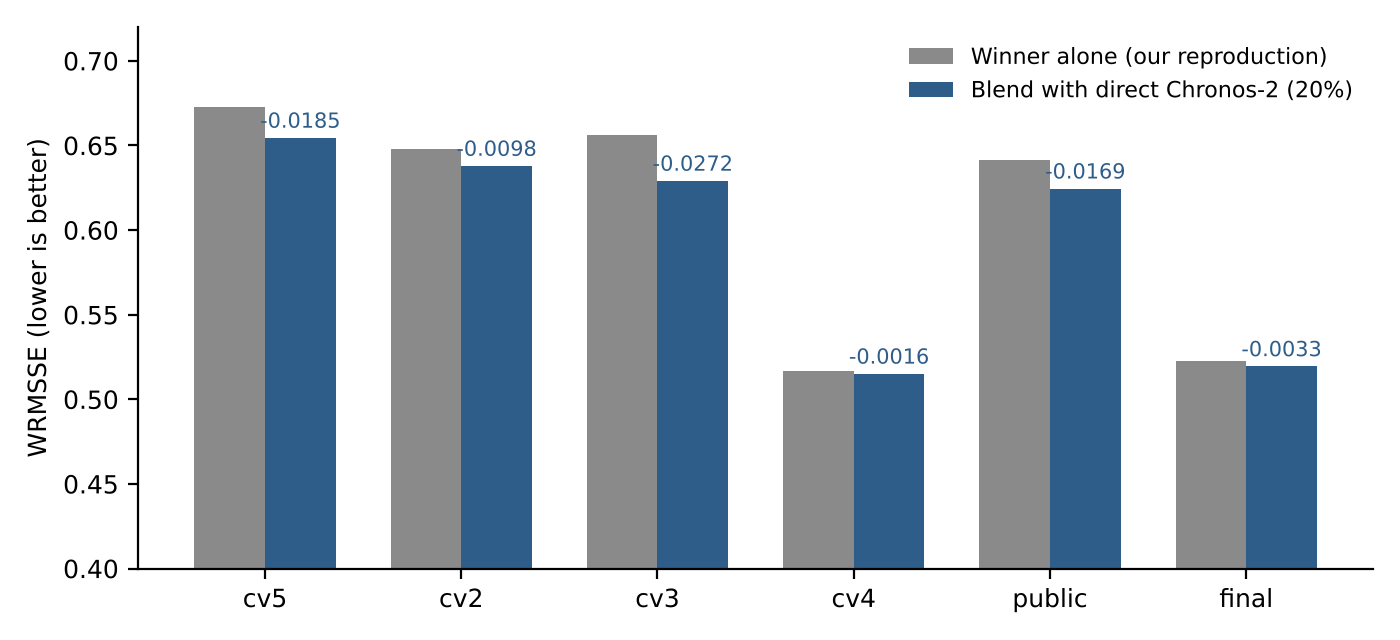

docs/figures/fig2.png


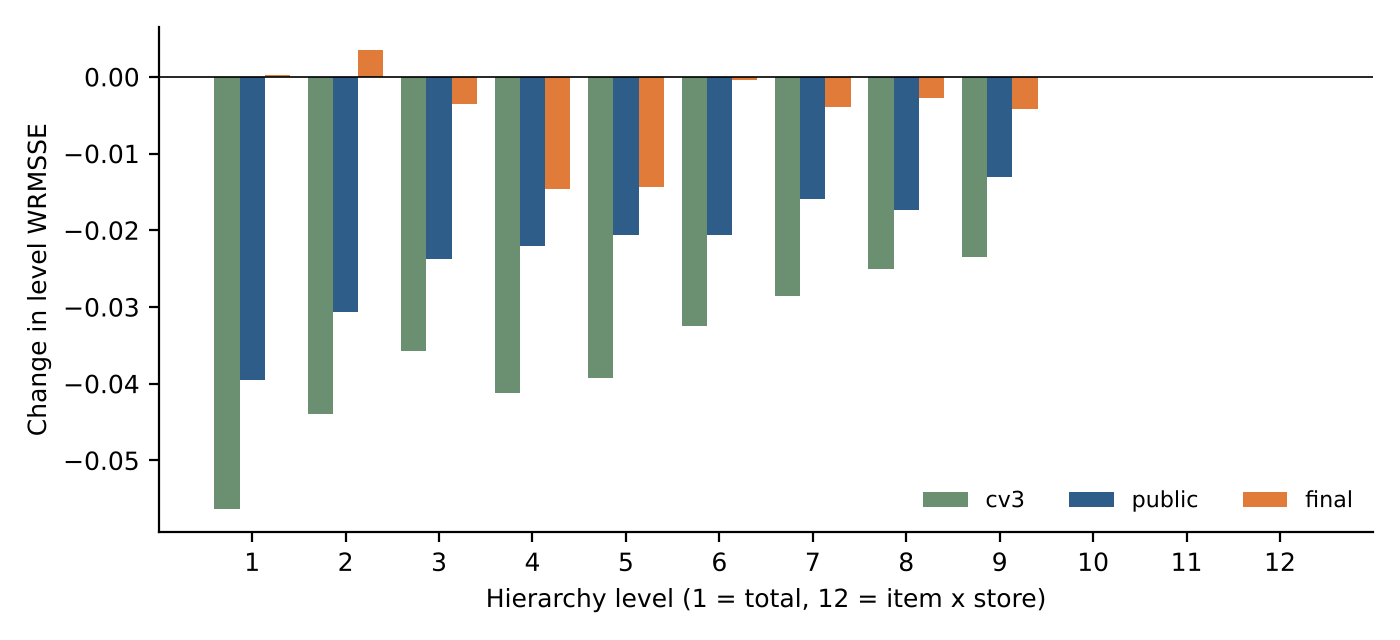

docs/figures/fig3.png


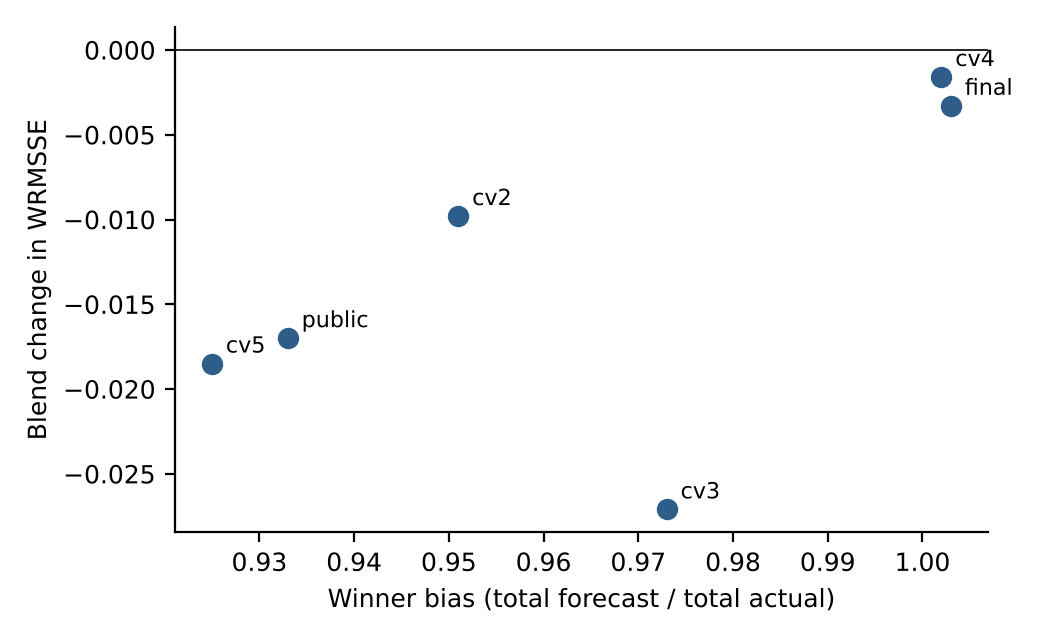

docs/figures/fig4.png


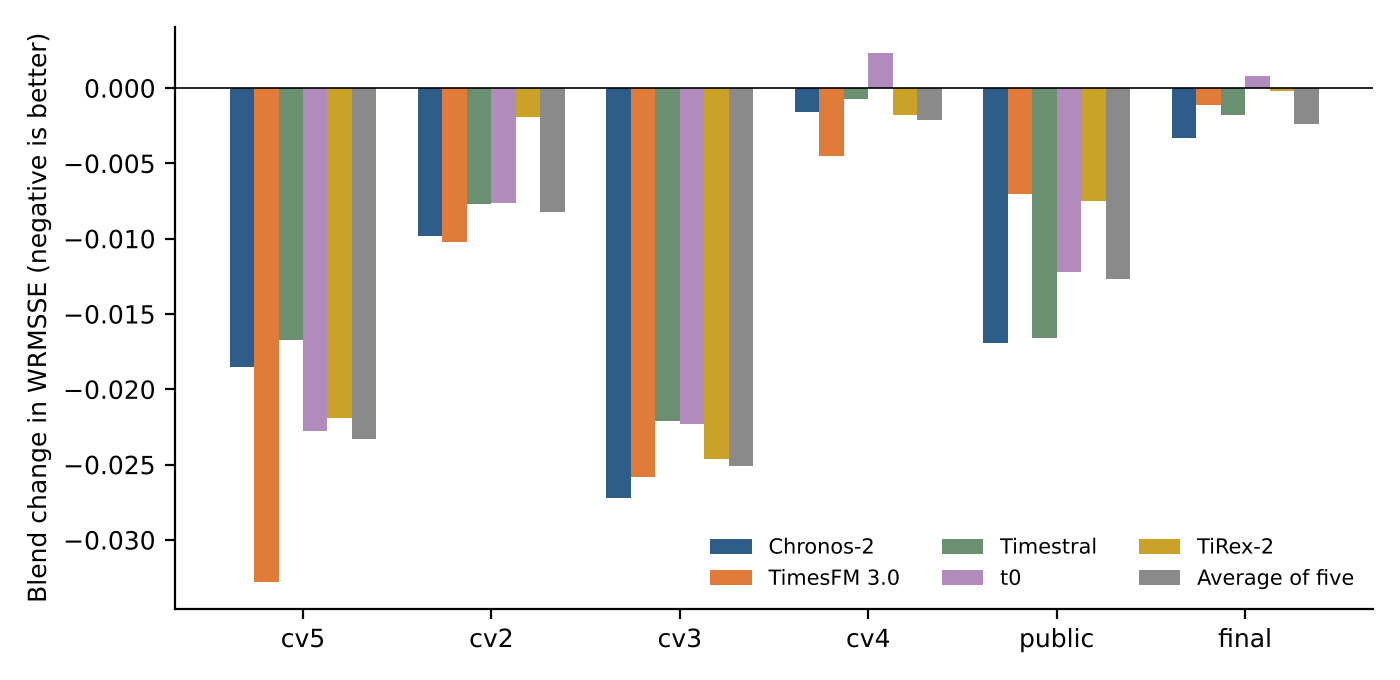

docs/figures/fig5.png


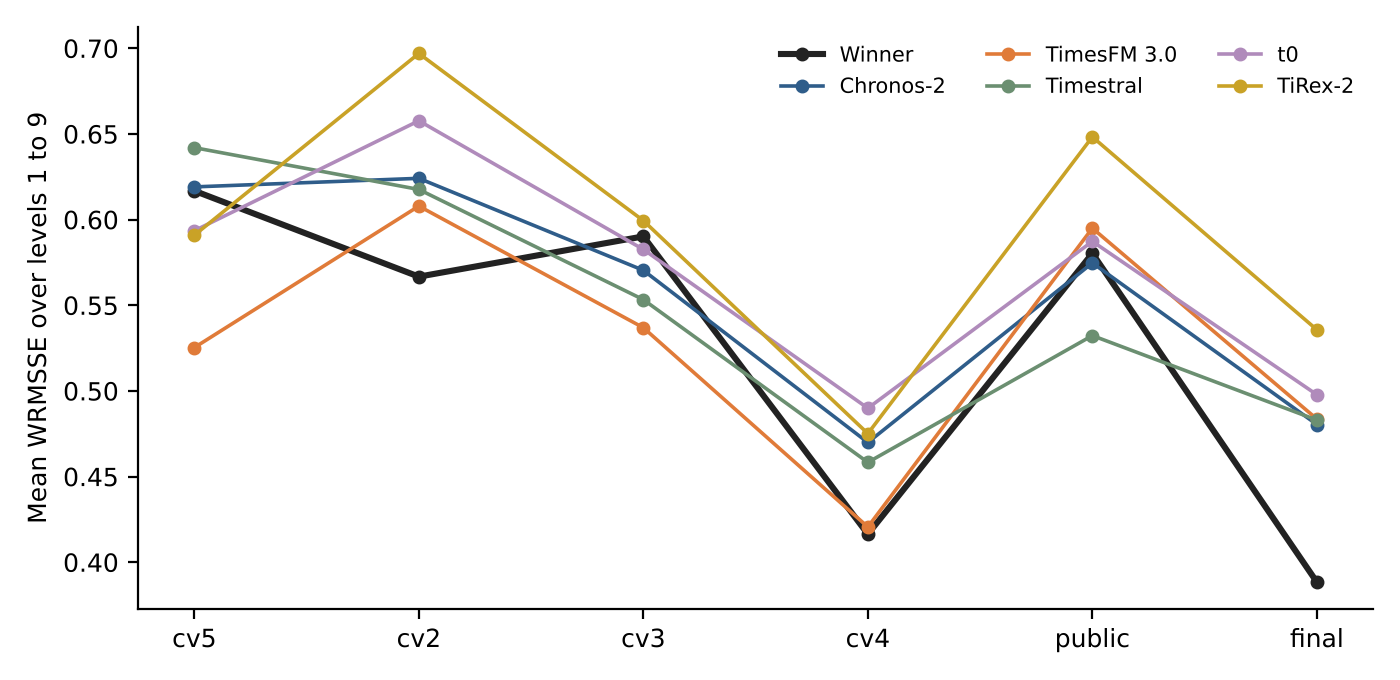

docs/figures/fig6.png


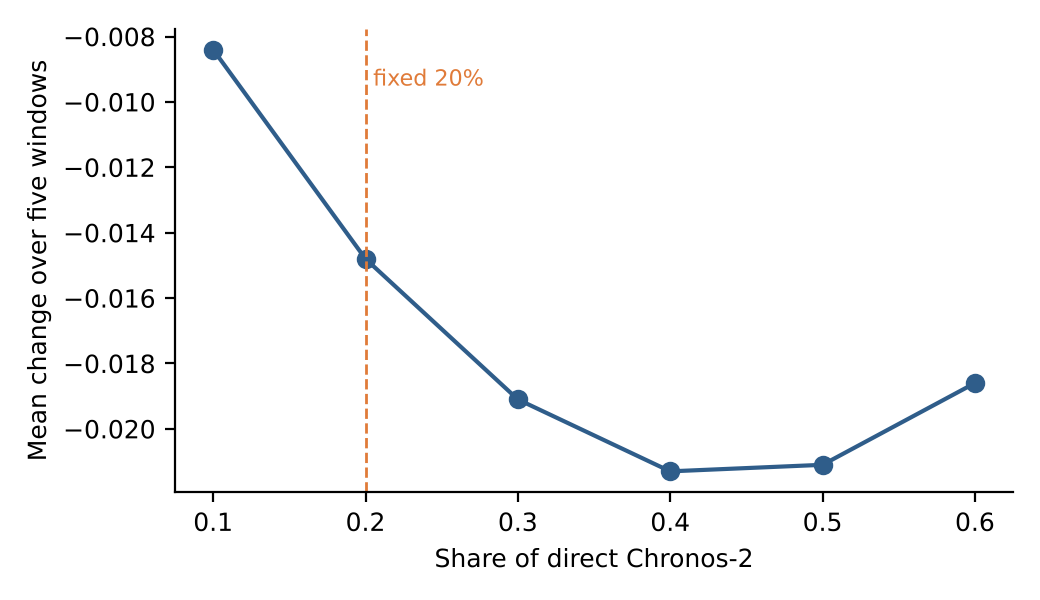

In [7]:
from IPython.display import Image, display
for f in sorted(glob.glob("docs/figures/fig*.png")):
    print(f); display(Image(f))

## 4. Other models and item levels

TimesFM 3.0, Timestral, t0 and TiRex-2 results are in `results/05_foundation_models/results_fm_PC2.txt`, item levels in `results/09_levels_10_11/results_lvl1011.txt`. The scripts are `src/m5_fm_score.py` and `src/m5_lvl1011.py`.

In [8]:
print(open("results/05_foundation_models/results_fm_PC2.txt").read()[:6000])

FOUNDATION MODELS: standalone quality, then blend into the winner
Models found: t0, timesfm3, timestral, tirex2g | Chronos-2 B is the earlier reference. Days in data folder: 1969.
Blend rule fixed in advance: share 0.20, levels 1 to 9 only, levels 10 to 12 stay as the winner. Lower WRMSSE is better.

PART 1: STANDALONE (direct forecasts of levels 1 to 9, scored as in the earlier Chronos-2 table)

WINDOW cv5 (forecast d_1802..d_1829), standalone WRMSSE per level, direct forecasts of the summed series
Level                             winner     Chronos-2 B              t0        timesfm3       timestral         tirex2g
------------------------------------------------------------------------------------------------------------------------
 1 Total                          0.5700          0.5715          0.5170          0.3895          0.6329          0.4639
 2 State                          0.5876          0.5754          0.5474          0.4543          0.5921          0.5688
 3 Store   